# DrawSense: training, algorithm selection and artifact export

**Goal:** train every algorithm on the historical results, pick the best one using an honest chronological
procedure, and export it to `artifacts/best_model/`. The DrawSense app (`uv run streamlit run app.py`) loads
that artifact and prints the **next 5 ranked six-number sets**.

**Input columns used:** `draw_date, n1, n2, n3, n4, n5, n6, additional` (all other columns are ignored).

> TOTO draws are random. A fair 6/49 draw gives every number a 6/49 = 12.245% chance, and every six-number set
> the same 1 in 13,983,816 chance of winning Group 1. This notebook measures whether any model beats random
> selection *on draws it never saw*, and reports the answer as it is.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from toto_ml.artifact import (DEFAULT_ARTIFACT_DIR, leaderboard_frame, load_artifact, predict_next,
                              save_artifact, select_best)
from toto_ml.config import BASELINE_P, load_config
from toto_ml.data import validate_and_clean
from toto_ml.data.ingest import draws_to_matrix
from toto_ml.evaluation import EXPECTED, run_experiment
from toto_ml.features import build_features
from toto_ml.models import LABELS
from toto_ml.store import STORE_PATH

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 4)

# Your results file. Draws added in the DrawSense app ("Add results" tab) are appended to it.
CSV_PATH = STORE_PATH                                   # toto_results.csv
ARTIFACT_DIR = DEFAULT_ARTIFACT_DIR                     # artifacts/best_model
COLUMNS = ["draw_date", "n1", "n2", "n3", "n4", "n5", "n6", "additional"]
cfg = load_config()                       # configs/default.yaml (seed, windows, split, model params)
print("seed:", cfg["seed"], "| test fraction:", cfg["split"]["test_fraction"], "| refit every:", cfg["split"]["refit_every"], "draws")

seed: 42 | test fraction: 0.2 | refit every: 10 draws


## 1. Load and validate the data (8 columns only, from `toto_results.csv`)

In [2]:
raw = pd.read_csv(CSV_PATH, usecols=lambda c: c in COLUMNS)[COLUMNS]
draws, report, excluded = validate_and_clean(raw)
print(f"rows read: {report['n_rows_raw']} | valid draws: {report['n_valid_draws']} | excluded: {report['n_excluded']}")
print(f"date range: {report['date_min']} -> {report['date_max']}")
for w in report["warnings"]:
    print("note:", w)
draws[COLUMNS].tail()

rows read: 313 | valid draws: 313 | excluded: 0
date range: 2023-11-20 -> 2026-11-16
note: No draw_number column: draws are labelled 1..N in date order.


,draw_date,n1,n2,n3,n4,n5,n6,additional
308,2026-11-02,8,10,19,37,40,48,38
309,2026-11-05,6,13,31,34,40,45,20
310,2026-11-09,5,27,29,38,40,43,4
311,2026-11-12,17,24,30,31,44,49,32
312,2026-11-16,2,22,24,31,36,43,41


## 2. Quick look: how often each number was drawn

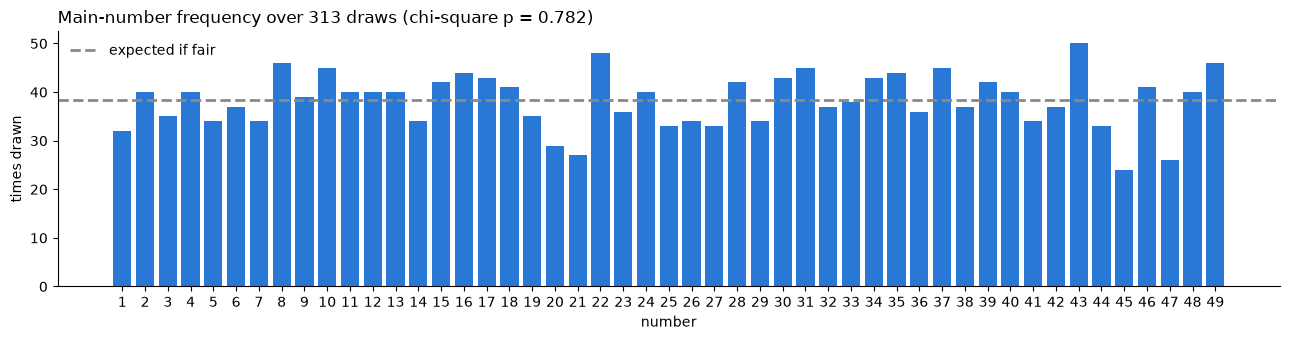

p >= 0.05 means the frequencies are consistent with a fair, uniform draw.


In [3]:
from scipy.stats import chisquare
M = draws_to_matrix(draws)
counts = M.sum(0)
chi = chisquare(counts)
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(range(1, 50), counts, color="#2a78d6")
ax.axhline(len(draws) * BASELINE_P, color="#8a8984", ls="--", lw=2, label="expected if fair")
ax.set_xticks(range(1, 50)); ax.set_xlabel("number"); ax.set_ylabel("times drawn"); ax.legend(frameon=False)
ax.set_title(f"Main-number frequency over {len(draws)} draws (chi-square p = {chi.pvalue:.3f})", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print("p >= 0.05 means the frequencies are consistent with a fair, uniform draw." if chi.pvalue >= 0.05 else
      "p < 0.05: some deviation from uniform; with 49 numbers this can happen by chance.")

## 3. Features (computed only from earlier draws)

For each upcoming draw and each number 1–49: overall frequency, rolling frequency over the last 10/20/50/100
draws, exponentially weighted frequency, draws since last seen and gap statistics, appearance in the last
draw(s), pair co-occurrence with the last draw's numbers, odd/even, number range, and context from the previous
draw (sum, odd count, consecutive numbers). The target is whether the number appears among the six main numbers.

In [4]:
fs = build_features(draws, cfg)
print(len(fs.feature_names), "features:", ", ".join(fs.feature_names))
fs.frame[fs.frame["t"] == fs.T - 1][["num"] + fs.feature_names[:10] + ["target"]].head(8)

31 features: freq_all, freq_10, freq_20, freq_50, freq_100, ewm_0.05, ewm_0.15, gap, gap_ratio, mean_gap, std_gap, max_gap, gap_z, in_last_1, hits_last_3, additional_freq, pair_with_prev, pair_max, pair_top5_mean, neighbor_in_prev, number, is_odd, decade, is_low, prev_sum, prev_odd_count, prev_consecutive, prev_range, ctx_mean_sum, ctx_parity_share, ctx_decade_share_ratio


,num,freq_all,freq_10,freq_20,freq_50,freq_100,ewm_0.05,ewm_0.15,gap,gap_ratio,mean_gap,target
13818,1,0.1026,0.0,0.00,0.02,0.07,0.0182,0.0007,33.0,4.0408,7.3871,0.0
13819,2,0.1250,0.1,0.05,0.06,0.09,0.0553,0.0484,7.0,0.8571,6.9737,1.0
13820,3,0.1122,0.0,0.05,0.08,0.12,0.0769,0.0302,11.0,1.3469,7.7353,0.0
13821,4,0.1282,0.1,0.10,0.12,0.15,0.1077,0.0772,5.0,0.6122,5.9744,0.0
13822,5,0.1090,0.2,0.15,0.12,0.13,0.1481,0.2291,1.0,0.1224,7.8788,0.0
13823,6,0.1186,0.1,0.15,0.12,0.15,0.1298,0.1287,2.0,0.2449,7.4722,0.0
13824,7,0.1090,0.0,0.15,0.16,0.14,0.1314,0.0400,14.0,1.7143,7.7273,0.0
13825,8,0.1474,0.2,0.20,0.16,0.15,0.1794,0.1638,3.0,0.3673,5.6444,0.0


## 4. Train and benchmark all 11 algorithms

Timeline (chronological, no shuffling):

| period | used for |
|---|---|
| first `min_history` draws | warm-up for features only |
| development period | **walk-forward validation**: retrain every 10 draws on all earlier draws, predict the next 10 before seeing them; fits probability calibration and the ensemble |
| **final test** (last 20%) | untouched: models trained once on everything before it, then frozen |

Algorithms: random, historical frequency, exponentially weighted frequency, Logistic Regression, Random Forest,
Extra Trees, XGBoost, LightGBM, CatBoost, MLP, and a rank-average ensemble. Takes about 3 minutes.

In [5]:
t0 = time.time()
_seen = set()
def progress(frac, msg):
    key = msg.split(":")[0]
    if key not in _seen:
        _seen.add(key)
        print(f"[{frac * 100:5.1f}%] {msg}")

res = run_experiment(draws, cfg, progress=progress)
sp = res.split
dates = pd.to_datetime(draws["draw_date"])
print(f"\ndone in {time.time() - t0:.0f}s")
print(f"validation: {dates.iloc[sp.val_start].date()} -> {dates.iloc[sp.test_start - 1].date()} ({len(sp.val_states)} draws)")
print(f"final test: {dates.iloc[sp.test_start].date()} -> {dates.iloc[sp.T - 1].date()} ({len(sp.test_states)} draws)")

[  1.0%] Building leakage-free features


[  5.0%] Walk-forward validation: random
[  5.4%] random: walk-forward origin 1/16
[ 13.4%] frequency: walk-forward origin 1/16
[ 21.4%] ewm: walk-forward origin 1/16
[ 29.4%] logistic_regression: walk-forward origin 1/16


[ 37.4%] random_forest: walk-forward origin 1/16


[ 45.4%] extra_trees: walk-forward origin 1/16


[ 53.4%] xgboost: walk-forward origin 1/16


[ 61.4%] lightgbm: walk-forward origin 1/16


[ 69.4%] catboost: walk-forward origin 1/16


[ 77.4%] mlp: walk-forward origin 1/16


[ 87.0%] Calibrating probabilities on development OOS predictions
[ 90.0%] Computing metrics, random simulations and significance tests


[ 95.0%] Computing SHAP feature importance


[100.0%] Done

done in 94s
validation: 2024-09-30 -> 2026-04-09 (160 draws)
final test: 2026-04-13 -> 2026-11-16 (63 draws)


### Development (validation) leaderboard: used to choose the model

In [6]:
lb = leaderboard_frame(res)
cols = ["label", "log_loss", "brier", "hits@6", "hits@10", "ndcg@10", "roc_auc", "ece"]
val = lb[lb["split"] == "validation"].sort_values("log_loss")[cols].reset_index(drop=True)
val

,label,log_loss,brier,hits@6,hits@10,ndcg@10,roc_auc,ece
0,CatBoost,0.3716,0.1074,0.7375,1.2750,0.1785,0.5144,1.0327e-02
1,MLP Neural Network,0.3717,0.1074,0.6250,1.1187,0.1465,0.5058,7.6624e-03
2,Historical frequency baseline,0.3718,0.1074,0.7000,1.2812,0.1683,0.5087,8.3583e-03
3,Exponentially weighted frequency,0.3718,0.1075,0.7937,1.2375,0.1708,0.5113,1.0057e-02
4,Ensemble ranking model,0.3718,0.1075,0.6937,1.2188,0.1612,0.5055,6.2206e-03
5,Extra Trees,0.3718,0.1075,0.7312,1.2312,0.1638,0.5066,4.8659e-03
6,Logistic Regression,0.3718,0.1075,0.6813,1.1875,0.1677,0.5009,9.4588e-03
7,Random Forest,0.3718,0.1075,0.6687,1.2437,0.1626,0.4974,1.0815e-02
8,XGBoost,0.3718,0.1075,0.7500,1.2063,0.1683,0.4998,9.3463e-03
9,LightGBM,0.3718,0.1075,0.7438,1.1938,0.1651,0.5026,7.5766e-03


### Final test leaderboard: unseen draws, identical for every model

In [7]:
test = lb[lb["split"] == "test"].sort_values("hits@10", ascending=False)
test[["label", "hits@6", "hits@10", "top6_2plus_rate", "top6_3plus_rate", "map@10", "ndcg@10", "roc_auc",
      "log_loss", "brier", "ece", "p_hits10_holm"]].reset_index(drop=True)

,label,hits@6,hits@10,top6_2plus_rate,top6_3plus_rate,map@10,ndcg@10,roc_auc,log_loss,brier,ece,p_hits10_holm
0,Extra Trees,0.7460,1.3968,0.1429,0.0159,0.0831,0.1901,0.5098,0.3718,0.1075,0.0199,0.8746
1,Ensemble ranking model,0.6825,1.3333,0.1587,0.0317,0.0878,0.1894,0.4972,0.3718,0.1075,0.0104,1.0000
2,XGBoost,0.6825,1.2857,0.1270,0.0000,0.0786,0.1790,0.5057,0.3718,0.1075,0.0099,1.0000
3,Random selection baseline,0.7778,1.2698,0.1905,0.0159,0.0889,0.1889,0.5000,0.3718,0.1075,0.0032,NaN
4,CatBoost,0.6984,1.2698,0.1270,0.0317,0.0790,0.1779,0.5079,0.3717,0.1074,0.0106,1.0000
5,LightGBM,0.8571,1.2381,0.1270,0.0159,0.0793,0.1796,0.5004,0.3718,0.1075,0.0149,1.0000
6,Random Forest,0.7302,1.1905,0.1429,0.0159,0.0657,0.1591,0.4925,0.3718,0.1075,0.0090,1.0000
7,Exponentially weighted frequency,0.6667,1.1746,0.0794,0.0159,0.0678,0.1594,0.5076,0.3718,0.1075,0.0090,1.0000
8,Historical frequency baseline,0.6667,1.1111,0.1270,0.0000,0.0633,0.1483,0.4804,0.3719,0.1075,0.0176,1.0000
9,Logistic Regression,0.6825,1.1111,0.0952,0.0317,0.0697,0.1536,0.4918,0.3718,0.1075,0.0148,1.0000


In [8]:
print(f"Random expectation: hits@6 = {EXPECTED['hits@6']:.4f}, hits@10 = {EXPECTED['hits@10']:.4f}, "
      f"log loss = {EXPECTED['log_loss']:.5f}")
null = res.significance["null"]["hits10"]
print(f"Random rankings over these exact test draws: hits@10 95% range {null['q025']:.3f} - {null['q975']:.3f}")
print(res.significance["summary"])

Random expectation: hits@6 = 0.7347, hits@10 = 1.2245, log loss = 0.37178
Random rankings over these exact test draws: hits@10 95% range 1.000 - 1.476
No model shows statistically significant out-of-sample improvement over random selection. This is the expected result for a fair, independent lottery.


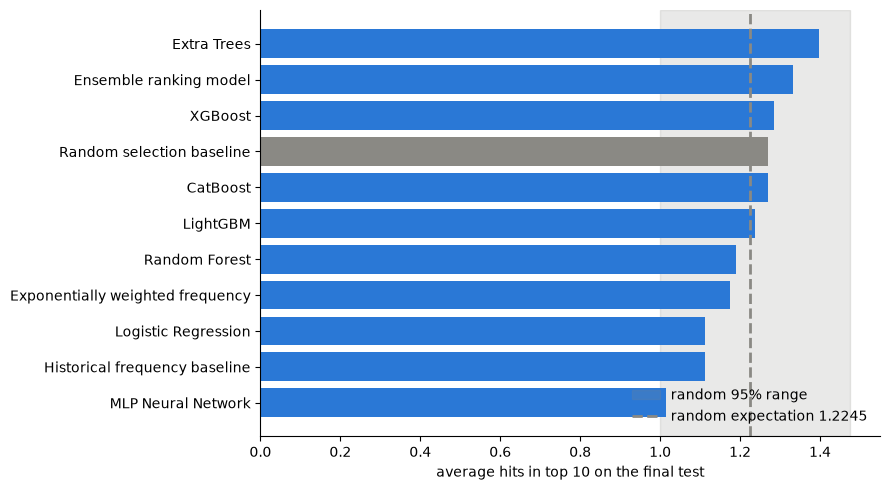

In [9]:
t = test.sort_values("hits@10")
fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(null["q025"], null["q975"], color="#8a8984", alpha=0.18, label="random 95% range")
ax.barh(t["label"], t["hits@10"], color=["#8a8984" if m == "random" else "#2a78d6" for m in t["model"]])
ax.axvline(EXPECTED["hits@10"], color="#8a8984", ls="--", lw=2, label="random expectation 1.2245")
ax.set_xlabel("average hits in top 10 on the final test"); ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 5. Pick the best algorithm

**Rule:** the lowest **log loss on the development period** (random excluded). Log loss scores all 49
calibrated probabilities on every draw, so it is far less noisy than counting hits. The final test is
**not** used for selection; it only reports how the chosen model did on unseen draws.

In [10]:
best, selection = select_best(res)
print("Best algorithm:", LABELS[best])
selection[["label", "log_loss", "brier", "hits@10", "ndcg@10"]].head(5)

Best algorithm: CatBoost


,label,log_loss,brier,hits@10,ndcg@10
0,CatBoost,0.3716,0.1074,1.2750,0.1785
1,MLP Neural Network,0.3717,0.1074,1.1187,0.1465
2,Historical frequency baseline,0.3718,0.1074,1.2812,0.1683
3,Exponentially weighted frequency,0.3718,0.1075,1.2375,0.1708
4,Ensemble ranking model,0.3718,0.1075,1.2188,0.1612


In [11]:
bt = next(r for r in res.leaderboard["test"] if r["model"] == best)
sig = res.significance["models"][best]
print(f"{LABELS[best]} on the final test ({bt['n_draws']} unseen draws):")
print(f"  hits@6  {bt['hits@6']:.3f}  (random {EXPECTED['hits@6']:.3f})")
print(f"  hits@10 {bt['hits@10']:.3f}  (random {EXPECTED['hits@10']:.4f}),  95% CI "
      f"{sig['boot_hits10_minus_expected']['ci_low'] + EXPECTED['hits@10']:.2f} - "
      f"{sig['boot_hits10_minus_expected']['ci_high'] + EXPECTED['hits@10']:.2f}")
print(f"  log loss {bt['log_loss']:.5f} (uniform {EXPECTED['log_loss']:.5f})")
print(f"  p-value vs random {sig['p_hits10_vs_random_sim']:.3f}, Holm-adjusted {sig['p_hits10_holm']:.3f}")
print("  verdict:", sig["verdict"])

CatBoost on the final test (63 unseen draws):
  hits@6  0.698  (random 0.735)
  hits@10 1.270  (random 1.2245),  95% CI 1.06 - 1.51
  log loss 0.37172 (uniform 0.37178)
  p-value vs random 0.365, Holm-adjusted 1.000
  verdict: No statistically significant evidence of beating random selection.


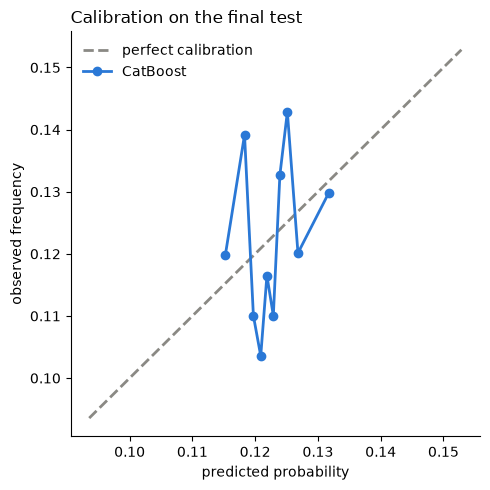

In [12]:
rel = res.reliability[best]["test"]["bins"]
fig, ax = plt.subplots(figsize=(5, 5))
x = [b["mean_predicted"] for b in rel]; y = [b["fraction_positive"] for b in rel]
lo, hi = min(x + y) - 0.01, max(x + y) + 0.01
ax.plot([lo, hi], [lo, hi], "--", color="#8a8984", lw=2, label="perfect calibration")
ax.plot(x, y, "o-", color="#2a78d6", lw=2, label=LABELS[best])
ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency"); ax.legend(frameon=False)
ax.set_title("Calibration on the final test", loc="left"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Export the artifact

The exported model was refitted on **all** draws (evaluation is finished), so it uses the most recent history.
Its probability calibrator is fitted on out-of-sample predictions only.

In [13]:
out = save_artifact(res, best, draws, ARTIFACT_DIR, selection_table=selection)
for f in sorted(out.iterdir()):
    print(f"{f.name:<18}{f.stat().st_size / 1024:8.1f} KB")

history.csv            9.8 KB
leaderboard.csv        9.9 KB
metadata.json          2.5 KB
model.joblib          42.8 KB
selection.csv          4.3 KB


## 7. Use the artifact: next 5 ranked sets

This is exactly what the web UI calls.

In [14]:
bundle = load_artifact(ARTIFACT_DIR)
pred = predict_next(bundle, n_sets=5)
print(f"Model: {pred['model']} | history up to {pred['based_on']['last_draw_date']} | next draw: {pred['next_draw_date']}\n")
pd.DataFrame([{"rank": s["rank"], **{f"n{i + 1}": n for i, n in enumerate(s["numbers"])},
               "avg_probability": f"{s['mean_probability']:.3%}", "number_ranks": s["number_ranks"],
               "odd/even": f"{s['odd']}/{s['even']}", "sum": s["sum"]} for s in pred["sets"]]).set_index("rank")

Model: CatBoost | history up to 2026-11-16 | next draw: 2026-11-19



,n1,n2,n3,n4,n5,n6,avg_probability,number_ranks,odd/even,sum
rank,,,,,,,,,,
1,10,12,14,15,38,45,13.229%,"[2, 5, 3, 6, 4, 1]",2/4,134
2,10,14,24,45,48,49,13.136%,"[2, 3, 8, 1, 7, 9]",2/4,190
3,10,26,28,38,45,48,13.095%,"[2, 10, 11, 4, 1, 7]",1/5,195
4,10,12,24,26,32,45,13.062%,"[2, 5, 8, 10, 12, 1]",1/5,149
5,10,15,28,32,45,49,13.048%,"[2, 6, 11, 12, 1, 9]",3/3,179


In [15]:
print("Top 10 numbers:")
pd.DataFrame(pred["numbers"][:10])[["rank", "number", "probability", "score", "hist_freq", "recent_count", "last_seen_date"]]

Top 10 numbers:


,rank,number,probability,score,hist_freq,recent_count,last_seen_date
0,1,45,0.1479,0.2247,0.0767,2,2026-11-05
1,2,10,0.1331,0.1692,0.1438,1,2026-11-02
2,3,14,0.1291,0.1536,0.1086,1,2026-09-28
3,4,38,0.1281,0.1495,0.1182,1,2026-11-09
4,5,12,0.1278,0.1482,0.1278,3,2026-10-22
5,6,15,0.1278,0.1482,0.1342,1,2026-10-19
6,7,48,0.1271,0.1454,0.1278,5,2026-11-02
7,8,24,0.1256,0.1394,0.1278,5,2026-11-16
8,9,49,0.1254,0.1385,0.1470,2,2026-11-12
9,10,26,0.1251,0.1371,0.1086,2,2026-10-01


**How to read this:** the sets are ranked by the model's estimates, but the final test above shows whether
those estimates beat random selection on unseen draws. Unless the verdict says a model is significantly better,
treat the sets as no more likely to win than any other six numbers.

Next step: `uv run streamlit run app.py`. Adding a new result there saves it to `toto_results.csv`,
re-runs this notebook automatically, and shows the new next 5 sets.